# Test-Stage Class-Level (Attribute) Performance

**Feeds:** RQ3 (span vs. attribute reliability, and whether the PT/EN gap
differs systematically at the attribute level).

Notebook 01 scores the attribute task across the four `cls_*` prompt variations
on the **prompt-selection** documents, because the question there is which
prompt component helps. In the **test** stage that question is already settled:
each (model, language) runs the single best (template, temperature)
configuration recorded in `best_configs.json`. The variant axis of notebook 01
therefore collapses, and the two views worth carrying over are the ones that do
not depend on it:

1. **Classification accuracy per model**, Portuguese beside English -- of the
   participants a run locates, the share it also types correctly.
2. **The participant budget table** -- annotated, located, typed correctly, and
   the accuracy those two counts imply.

Notebook 03 (`03_class_level_performance`) already covers the *per-class*
picture on the same runs (which types each model handles) and the span-to-
attribute ceiling gap. This notebook is the aggregate counterpart: it asks how
much of each model's extraction survives the type requirement, not which type is
responsible.

Only `cls_*` templates predict a type at all. A model whose selected test-stage
template is `ext_*` produces no attribute signal, and is reported as such rather
than shown as a zero -- absence here means *not asked to classify*, not *asked
and failed*. That distinction is itself a result: a run reaches the test stage on
an extract-only prompt because that prompt scored highest at span level.

Location subtypes are coarsened first (`c.coarsen_types`: any `Pl_*` -> `Loc`),
the headline convention for the document-level regime -- see notebook 08.

In [2]:
import sys
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import _common as c

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_rows", 100)

## Scoring the selected test-stage runs

`compute_extraction_classification_metrics` partitions one set of span-level
outcomes into the extraction and the classification counts, so `f1_ext` and
`f1_cls` share their denominators exactly and `tp_cls <= tp_ext` holds by
construction. The `*_cls` columns come back `NaN` for a group whose template
never predicts a type, which is how the extract-only runs identify themselves.

In [3]:
best_configs = c.load_best_configs()
detailed = pd.concat(
    [c.load_detailed("test", lang) for lang in c.LANGUAGE_ORDER],
    ignore_index=True,
)
best_detailed = c.coarsen_types(c.filter_to_best_configs(detailed, best_configs))

cls_scores = c.compute_extraction_classification_metrics(
    best_detailed, group_cols=["language", "model"]
)
cls_scores = cls_scores[cls_scores["model"].isin(c.MODEL_ORDER)].reset_index(drop=True)

# The configuration each row was produced by, so the table and the chart can
# name it without re-reading best_configs.json.
config = (
    best_detailed.drop_duplicates(["language", "model"])
    [["language", "model", "base_template", "temperature"]]
)
cls_scores = cls_scores.merge(config, on=["language", "model"], how="left")

ext_only = cls_scores[cls_scores["f1_cls"].isna()]
print("No attribute signal (selected test-stage template is extract-only):")
for _, r in ext_only.sort_values(["language", "model"]).iterrows():
    print(f"  {r['language']:<11} {r['model']:<18} {r['base_template']}")
print(f"\n{len(cls_scores) - len(ext_only)} of {len(cls_scores)} "
      f"(model, language) runs classify.")

cls_scores[["language", "model", "base_template", "temperature",
            "f1_ext", "f1_cls"]].round(3)

No attribute signal (selected test-stage template is extract-only):
  english     gervasio_8b_ptpt   ext_def_exp
  english     qwen3_14b          ext_exp
  english     qwen3_8b           ext_def_exp
  portuguese  gervasio_8b_ptpt   ext_def_exp
  portuguese  qwen3_14b          ext_exp
  portuguese  qwen3_8b           ext_def_exp

12 of 18 (model, language) runs classify.


,language,model,base_template,temperature,f1_ext,f1_cls
0,english,amalia,cls_def_exp,0.3,0.105,0.080
1,english,euro_llm_9b,cls_def_exp,0.6,0.242,0.169
2,english,gemini,cls_def_exp,0.6,0.542,0.469
3,english,gemma3_12b,cls_exp,0.6,0.370,0.303
4,english,gemma3_4b,cls_def_exp,0.3,0.270,0.225
5,english,gervasio_8b_ptpt,ext_def_exp,0.3,0.351,NaN
6,english,qwen3_14b,ext_exp,1.0,0.326,NaN
7,english,qwen3_4b,cls_exp,0.6,0.277,0.222
8,english,qwen3_8b,ext_def_exp,1.0,0.295,NaN
9,portuguese,amalia,cls_def_exp,0.3,0.169,0.134


## Participant budget per (model, language)

The same funnel notebook 01 reports per prompt variant, here per (model,
language) on the test documents. Every column is a re-presentation of
`cls_scores` -- nothing is re-scored.

| Column | Definition in terms of `cls_scores` |
| --- | --- |
| `f1_ext` | span-level strict F1, type ignored |
| `n_participants` | `tp_ext + fn_ext` -- every annotation is either matched or missed, so this is the annotated total |
| `n_extracted` | `tp_ext` -- annotated participants whose span was matched exactly |
| `n_typed_ok` | `tp_cls` -- span *and* type both correct |
| `acc_cls` | `tp_cls / tp_ext` -- typing accuracy over the participants already located |

`n_participants` is constant within a language, since every run sees the same
test documents, so `n_extracted / n_participants` is exactly the extraction
recall already carried in `cls_scores` -- asserted below so the table cannot
drift from the scored metric.

`acc_cls` is conditional on each run's own extraction and its denominator varies
widely across rows, so it is read next to `n_extracted` rather than on its own.

In [4]:
# n_extracted / n_participants must reproduce the extraction recall already
# scored in cls_scores, otherwise this table and the metrics above disagree.
_recall_check = (
    cls_scores["tp_ext"] / (cls_scores["tp_ext"] + cls_scores["fn_ext"])
    - cls_scores["recall_ext"]
).abs().max()
assert _recall_check < 1e-12, "n_extracted / n_participants disagrees with recall_ext"

participant_table = (
    cls_scores.assign(
        language=pd.Categorical(cls_scores["language"], categories=c.LANGUAGE_ORDER, ordered=True),
        model=pd.Categorical(cls_scores["model"], categories=c.MODEL_ORDER, ordered=True),
        n_participants=cls_scores["tp_ext"] + cls_scores["fn_ext"],
        n_extracted=cls_scores["tp_ext"],
        n_typed_ok=cls_scores["tp_cls"],
        acc_cls=cls_scores["tp_cls"] / cls_scores["tp_ext"],
    )
    .sort_values(["language", "model"])
    [["language", "model", "base_template", "temperature", "f1_ext",
      "n_participants", "n_extracted", "n_typed_ok", "acc_cls"]]
    .reset_index(drop=True)
)

print(
    "annotated participants per language: "
    + ", ".join(
        f"{lang} {n}"
        for lang, n in participant_table.groupby("language", observed=True)["n_participants"].first().items()
    )
)

participant_table.round({"f1_ext": 3, "acc_cls": 3})

annotated participants per language: portuguese 2580, english 2580


,language,model,base_template,temperature,f1_ext,n_participants,n_extracted,n_typed_ok,acc_cls
0,portuguese,gemini,cls_def_exp,1.0,0.553,2580,1434,1279.0,0.892
1,portuguese,gemma3_4b,cls_def_exp,0.6,0.258,2580,542,446.0,0.823
2,portuguese,gemma3_12b,cls_def_exp,0.3,0.335,2580,772,640.0,0.829
3,portuguese,qwen3_4b,cls_def_exp,0.6,0.246,2580,554,464.0,0.838
4,portuguese,qwen3_8b,ext_def_exp,1.0,0.288,2580,615,NaN,NaN
5,portuguese,qwen3_14b,ext_exp,1.0,0.327,2580,736,NaN,NaN
6,portuguese,amalia,cls_def_exp,0.3,0.169,2580,361,285.0,0.789
7,portuguese,euro_llm_9b,cls_def_exp,0.3,0.260,2580,565,433.0,0.766
8,portuguese,gervasio_8b_ptpt,ext_def_exp,0.6,0.360,2580,825,NaN,NaN
9,english,gemini,cls_def_exp,0.6,0.542,2580,1414,1224.0,0.866


## Classification accuracy per model

One bar per (model, language) that classifies at all: the share of the
participants a run located that it also typed correctly. Portuguese and English
sit side by side where both classify; where only one language's selected
template is a `cls_*` one, only that bar is drawn, in its own position, so the
gap is visible as a gap rather than closed up.

The count above each bar is `n_extracted`, the denominator the accuracy is taken
over. It varies by an order of magnitude across models, and a high accuracy on a
handful of located participants is not the same claim as the same accuracy on
several hundred, so the two numbers are shown together.

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\03_test_cls_accuracy_by_model.pdf


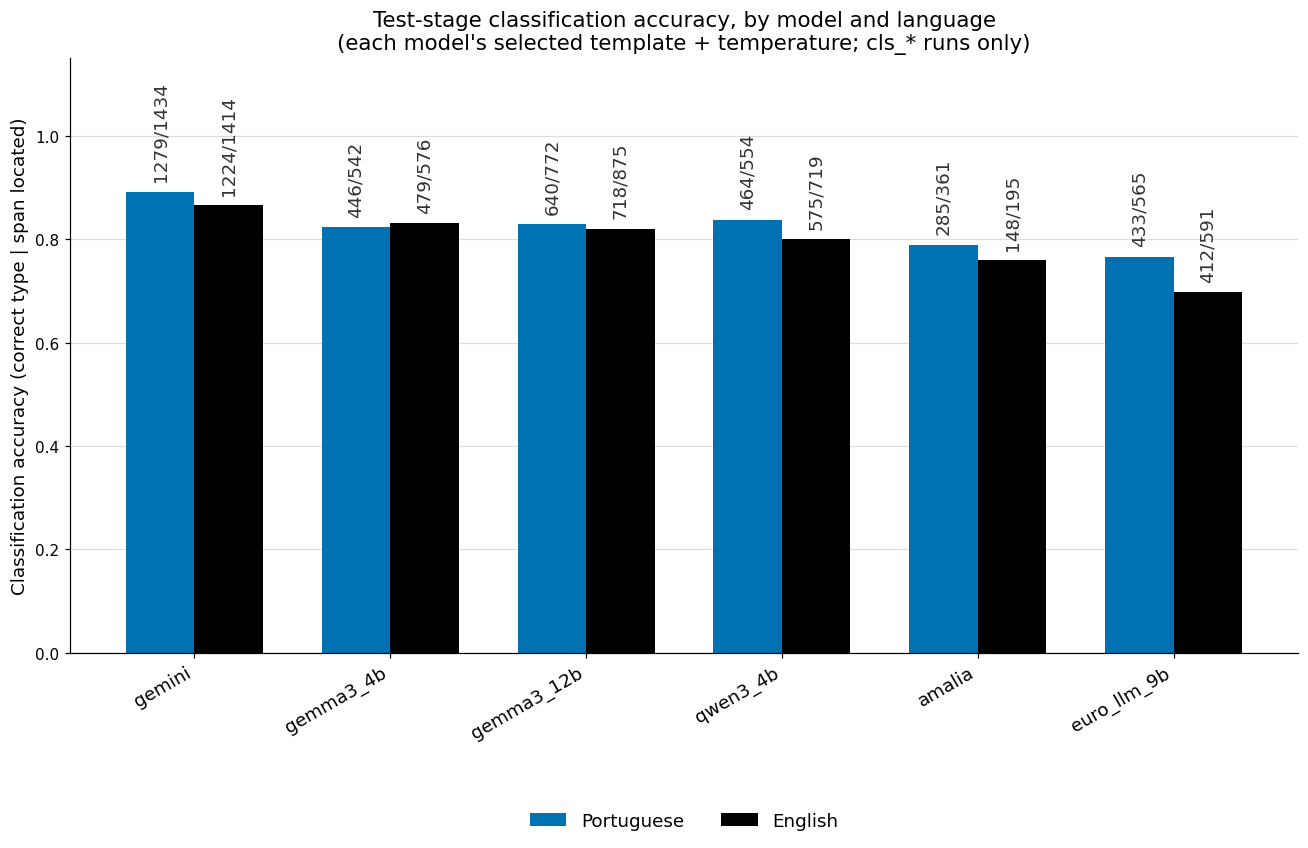

In [14]:
acc = participant_table.dropna(subset=["acc_cls"])
# Only the models that classify in at least one language reach the chart; the
# rest have no bar to draw, and their absence is reported above.
models = [m for m in c.MODEL_ORDER if m in set(acc["model"])]

fig, ax = plt.subplots(figsize=(12, 8))
x = np.arange(len(models))
width = 0.35
for i, lang in enumerate(c.LANGUAGE_ORDER):
    sub = acc[acc["language"] == lang].set_index("model").reindex(models)
    offset = (i - 0.5) * width
    ax.bar(x + offset, sub["acc_cls"].values, width=width,
           color=c.LANGUAGE_COLORS[lang], label=lang.capitalize(), zorder=2)
    # Accuracy is conditional on extraction, so every bar carries its own
    # denominator -- without it the short bars and the small samples are
    # indistinguishable.
    for xi, value, n, n_tp_ok in zip(x + offset, sub["acc_cls"].values, sub["n_extracted"].values, sub["n_typed_ok"].values):
        if np.isnan(value):
            # No bar to draw here. Say so in the slot, so the gap cannot be
            # read as an accuracy of zero.
            ax.text(xi, 0.02, "no cls_* run", ha="center", va="bottom",
                    fontsize=12, rotation=90, color="#777777")
            continue
        ax.text(xi, value + 0.02, f"{int(n_tp_ok)}/{int(n)}", ha="center", va="bottom",
                fontsize=12, rotation=90, color="#333333")

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=30, ha="right", fontsize=12)
ax.set_ylabel("Classification accuracy (correct type | span located)", fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_title("Test-stage classification accuracy, by model and language\n"
             "(each model's selected template + temperature; cls_* runs only)", fontsize=14)
# Every bar clears 0.7 and the n= labels reach the top of the axes, so the
# legend goes below rather than inside.
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2,
          frameon=False, fontsize=12)
c.style_axis(ax)
c.save_fig(fig, "03_test_cls_accuracy_by_model")
plt.show()

## Where the accuracy goes: per class, per model

The chart above gives one accuracy per run. That number is an average over the
participant types, and the types are not equally represented -- `Per`, `Org` and
`Loc` dominate the corpus (notebook 08) -- so a run can hold a high overall
accuracy while failing a class outright.

This grid decomposes it. One panel per model, the seven coarse classes on the
horizontal axis, Portuguese beside English. Each bar is the accuracy for that
class conditional on the span already being located: of the located
participants annotated as that class, the share the run also typed as that
class. Weighted by the counts printed above the bars, the bars of a panel
average back to that model's bar in the chart above (to within the handful of
matched spans whose gold type falls outside the prompt's label set, which are
not scoreable by class).

The support is printed above every bar because it varies from single figures to
several hundred within one panel, and a class with a dozen located participants
carries no weight against one with three hundred.

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\03_test_cls_accuracy_by_class.pdf


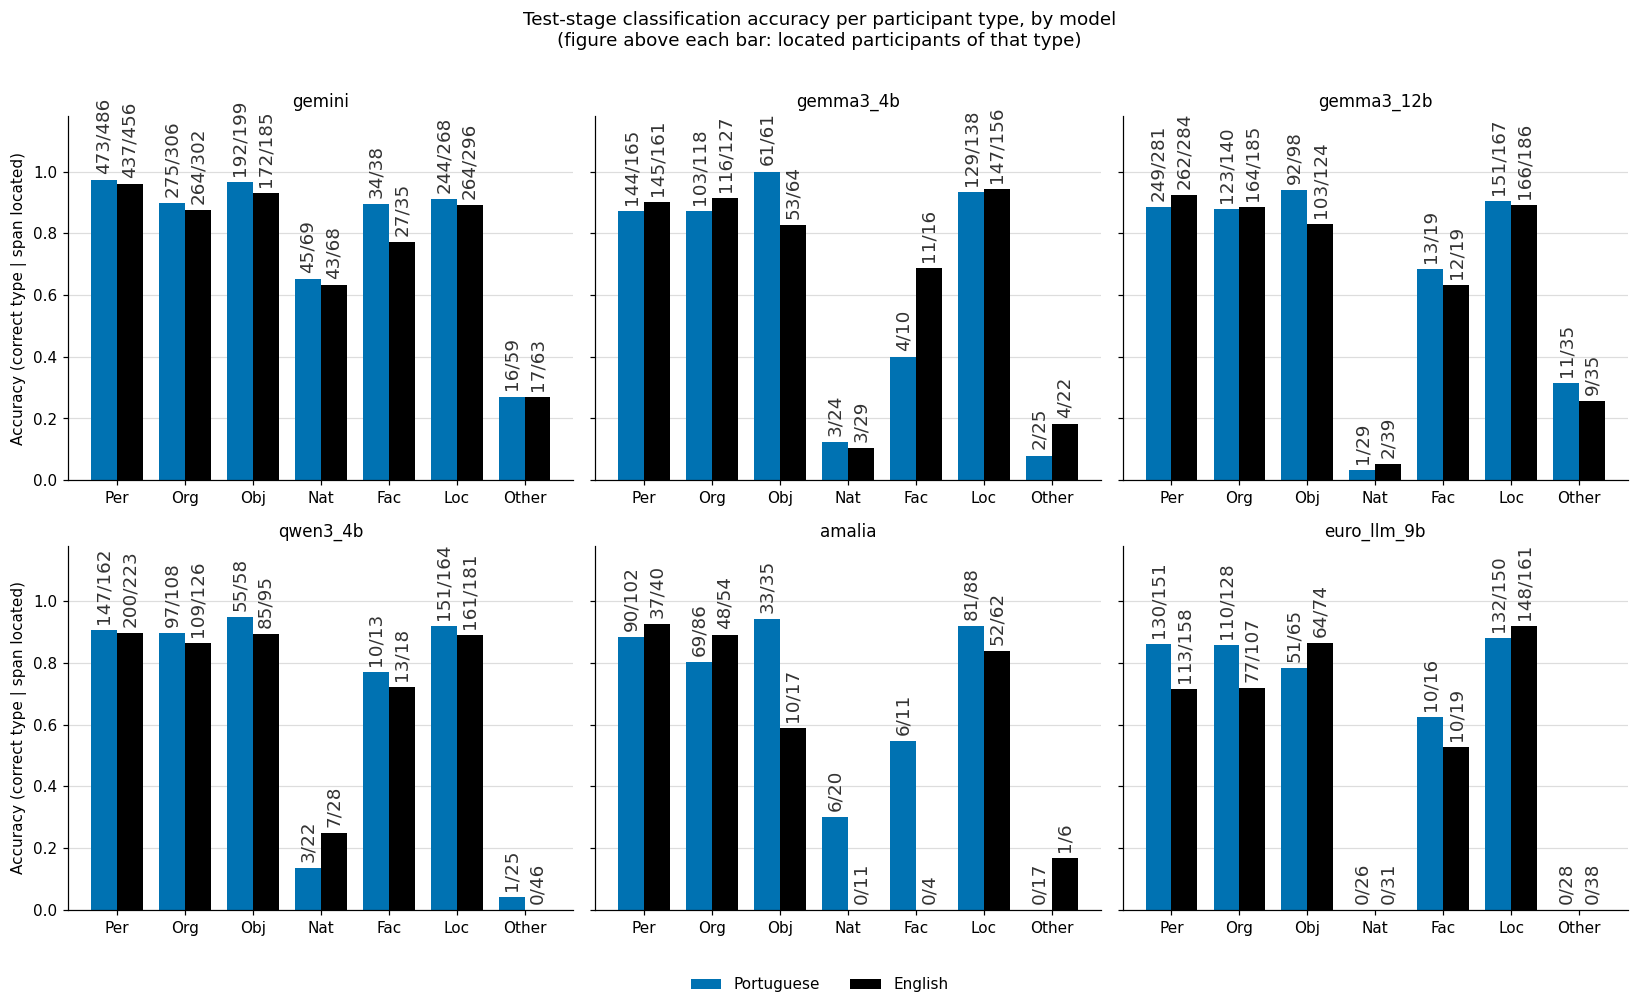

34 (model, class) pairs measured in both languages on >= 20 located participants each
  |PT - EN| > 0.15: 1;  > 0.10: 7

largest disagreements:
model        cls
gemma3_4b    Obj    0.172
euro_llm_9b  Per    0.146
             Org    0.140
gemini       Fac    0.123
qwen3_4b     Nat    0.114


In [6]:
# Per-class accuracy conditional on extraction, over the same eleven runs the
# chart above reports. Restricting to those runs first keeps the extract-only
# ones -- which predict no type anywhere -- out of the grid entirely, rather
# than drawing them as a row of zeros.
classifying = set(map(
    tuple,
    participant_table.dropna(subset=["acc_cls"])[["language", "model"]].values,
))
cls_only = best_detailed[[
    k in classifying
    for k in zip(best_detailed["language"], best_detailed["model"])
]]

per_class = c.compute_conditional_type_metrics(
    cls_only, group_cols=["language", "model"], per_class=True
)
CLASSES = c.PROMPT_CLASSES_COARSE
panel_models = [m for m in c.MODEL_ORDER if m in set(per_class["model"])]

ncols = 3
nrows = int(np.ceil(len(panel_models) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.6 * nrows),
                         sharey=True, squeeze=False)
x = np.arange(len(CLASSES))
width = 0.38

for ax, model in zip(axes.ravel(), panel_models):
    drawn = []
    for i, lang in enumerate(c.LANGUAGE_ORDER):
        sub = (per_class[(per_class["model"] == model) & (per_class["language"] == lang)]
               .set_index("cls").reindex(CLASSES))
        if sub["recall"].notna().any():
            drawn.append(lang)
        offset = (i - 0.5) * width
        ax.bar(x + offset, sub["recall"].values, width=width,
               color=c.LANGUAGE_COLORS[lang], label=lang.capitalize(), zorder=2)
        # Accuracy per class is conditional on a support that varies by two
        # orders of magnitude inside a single panel, so every bar carries it.
        for xi, value, n, tp in zip(x + offset, sub["recall"].values, sub["support"].values, sub["tp"].values):
            if np.isnan(value):
                continue
            ax.text(xi, value + 0.02, f"{int(tp)}/{int(n)}", ha="center", va="bottom",
                    fontsize=12, rotation=90, color="#333333")

    missing = [l for l in c.LANGUAGE_ORDER if l not in drawn]
    if missing:
        # A whole language absent means that model reached the test stage on an
        # extract-only variant there -- said once per panel rather than once
        # per empty slot.
        ax.text(0.5, 0.94, f"no {missing[0].capitalize()} cls_* run",
                transform=ax.transAxes,
                ha="center", va="top", fontsize=12, color="#777777")

    ax.set_xticks(x)
    ax.set_xticklabels(CLASSES, rotation=0)
    ax.set_ylim(0, 1.18)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_title(model, fontsize=11)
    c.style_axis(ax)

for ax in axes.ravel()[len(panel_models):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("Accuracy (correct type | span located)")

_h, _l = axes[0, 0].get_legend_handles_labels()
fig.legend(_h[:2], _l[:2], loc="lower center", ncol=2, frameon=False)
fig.suptitle("Test-stage classification accuracy per participant type, by model\n"
             "(figure above each bar: located participants of that type)")
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
c.save_fig(fig, "03_test_cls_accuracy_by_class", tight=False)
plt.show()

# How consistent is the per-class profile between the languages? Restricted to
# the (model, class) pairs measured in both, on at least 20 located
# participants each -- below that a difference is mostly sampling.
paired = per_class.pivot(index=["model", "cls"], columns="language",
                         values=["recall", "support"]).dropna()
enough = ((paired[("support", "portuguese")] >= 20)
          & (paired[("support", "english")] >= 20))
gap = (paired[("recall", "portuguese")] - paired[("recall", "english")]).abs()[enough]
print(f"{len(gap)} (model, class) pairs measured in both languages on >= 20 "
      f"located participants each")
print(f"  |PT - EN| > 0.15: {int((gap > 0.15).sum())};  > 0.10: {int((gap > 0.10).sum())}")
print("\nlargest disagreements:")
print(gap.sort_values(ascending=False).head(5).round(3).to_string())


In [7]:
per_class

,language,model,cls,support,tp,fp,fn,precision,recall,f1
0,english,amalia,Per,40,37,3,3,0.925000,0.925000,0.925000
1,english,amalia,Org,54,48,2,6,0.960000,0.888889,0.923077
2,english,amalia,Obj,17,10,9,7,0.526316,0.588235,0.555556
3,english,amalia,Nat,11,0,2,11,0.000000,0.000000,0.000000
4,english,amalia,Fac,4,0,2,4,0.000000,0.000000,0.000000
5,english,amalia,Loc,62,52,9,10,0.852459,0.838710,0.845528
6,english,amalia,Other,6,1,1,5,0.500000,0.166667,0.250000
7,english,euro_llm_9b,Per,158,113,20,45,0.849624,0.715190,0.776632
8,english,euro_llm_9b,Org,107,77,10,30,0.885057,0.719626,0.793814
9,english,euro_llm_9b,Obj,74,64,101,10,0.387879,0.864865,0.535565


## Synthesis

- Feeds **RQ3**. Of the 18 (model, language) test-stage runs, **11 classify and
  7 do not**: their selected template is `ext_*`, which never asks for a type.
  The exclusion is not uniform across languages -- `gemini` reaches the test
  stage on `cls_def_exp` in Portuguese but on `ext_def_exp` in English, so the
  strongest extractor in the study has no attribute signal at all in English.
  `gervasio_8b_ptpt`, `qwen3_8b` and `qwen3_14b` are extract-only in both.

- **Typing is not the bottleneck; locating is.** Both languages annotate 2580
  participants. The best run locates 1434 of them (`gemini`, Portuguese) and the
  weakest of the classifying runs locates 195 (`amalia`, English). Against that,
  classification accuracy over the located participants never drops below 0.707
  and reaches 0.892. Every classifying run therefore loses far more
  participants to extraction than to typing, which is the same conclusion the
  prompt-selection phase reaches in notebook 01 -- it survives the move to the
  full test corpus and to per-model best configurations.

- **The accuracies are tightly grouped.** Portuguese spans 0.766
  (`euro_llm_9b`) to 0.892 (`gemini`); English spans 0.707 (`euro_llm_9b`) to
  0.832 (`gemma3_4b`). Model size does not order them: `gemma3_4b` and
  `gemma3_12b` are within 0.01 of each other in both languages, and `qwen3_4b`
  is above both in Portuguese.

- **Portuguese types slightly better than English**, in four of the five models
  that classify in both: `qwen3_4b` (0.838 vs 0.803), `euro_llm_9b` (0.766 vs
  0.707), `amalia` (0.789 vs 0.759) and `gemma3_12b` (0.829 vs 0.821).
  `gemma3_4b` reverses it by 0.009 (0.823 vs 0.832). The direction is consistent
  but the margins are small, and `n_extracted` differs between the two languages
  for every model, so each accuracy is taken over a different subset of the
  corpus -- read this as "no systematic English advantage at the attribute
  level", not as a measured Portuguese advantage.

- **The overall accuracy hides a split between the classes.** `Per`, `Org`,
  `Loc` and `Obj` are handled well by every run -- the lowest bar across `Per`,
  `Org` and `Loc` in the whole grid is 0.697 (`euro_llm_9b`, English `Per`), and
  `Obj` only dips under `amalia` in English (0.588). `Nat` and `Other` collapse:
  apart from `gemini`, no run exceeds 0.300 on `Nat` or 0.314 on `Other`, and
  `euro_llm_9b` scores 0.000 on both in both languages. `gemini` is the only run to make real headway on
  `Nat` (0.652), and even it reaches only 0.271 on `Other`. `Fac` sits in
  between and is the least stable class, though its support rarely exceeds 20.

- **The per-class profile is a property of the class, not the language.** Of the
  27 (model, class) pairs measured in both languages on at least 20 located
  participants each, only two differ by more than 0.15: `gemma3_4b` on `Obj`
  (1.000 Portuguese against 0.828 English) and `euro_llm_9b` on `Per` (0.861
  against 0.697). The shape of each panel -- high on the three frequent classes,
  near zero on `Nat` and `Other` -- repeats across the two languages of the same
  model. This is the attribute-level counterpart of the extraction result in
  RQ2: the same classes fail in both languages.

- Notebook 03 (`03_class_level_performance`) breaks the same runs down by class
  and reports the span-to-attribute ceiling gap; this notebook only reports how
  much of the located set survives the type requirement in aggregate.